
---
date: "2026-10-23"
date-modified: last-modified
format:
  html:
    toc: true
---


# Lebesgue Outer Measure

**Prerequisites:** [Measures and Measure Spaces](measure.ipynb) · [Almost Everywhere, σ-Finite Measures, and Completeness](measure-properties-and-completion.ipynb) · [Supremum and Infimum](supremum-infimum.ipynb) · [Compactness](compactness.ipynb)

The examples of measures so far (counting and Dirac measures) are mainly instructive. The first serious example is **Lebesgue measure** on $\mathbb{R}^n$: the measure that is length on $\mathbb{R}$, area on $\mathbb{R}^2$, volume on $\mathbb{R}^3$, and $n$-dimensional volume in general. Building it takes several steps, and the techniques are general: many other measures, on spaces that are not Euclidean at all, are constructed the same way. The first step is the **outer measure**, defined for every subset of $\mathbb{R}^n$ by approximating the set from outside with boxes.

We work in $\mathbb{R}^n$ from the start. Many texts first construct the measure on $\mathbb{R}$ only and reach $\mathbb{R}^n$ later through product measures. The general case is no harder, the proofs are almost identical, and pictures in the plane show much more than pictures on a line, where all sets are squeezed together.

## 1\. Which Sizes Must Be Given?

Length is known for intervals, area for rectangles (length times width), volume for boxes. Is that enough? Using only the [axioms of a measure](measure.ipynb#def-measure) and the areas of rectangles, can we obtain the areas of all the usual shapes?

- **A triangle.** Put it inside a rectangle and drop an altitude. The school argument says each small triangle is half of a rectangle because the two halves are congruent: one is the other turned by $180°$. That uses an extra axiom, that rigid motions preserve area. One can build measure theory that way (a more geometric approach), but we do not need it: the goal is a well-defined measure, not a method of computation. Once measure is connected with the integral, all integration techniques are available for computing areas.
- **A disc.** Fill the inside with rectangles: a square in the middle, rectangles in the gaps, smaller ones in the remaining gaps, and so on ([figure](why-measure-theory.ipynb#why-additivity-must-be-countable)). The open disc becomes a countable union of rectangles, and countable additivity gives its area. The rectangles touch along their edges, but edges have area zero, as we now see, so they do no harm. Axis-parallel rectangles suffice.
- **A segment.** A horizontal segment of length $L$ lies in a rectangle $R_\varepsilon$ of height $\varepsilon$. By monotonicity its area is at most $\varepsilon L$ for every $\varepsilon > 0$, hence $0$.
- **A circle** (the boundary of a disc). Cover it by about $1/\varepsilon$ squares of side about $\varepsilon$. The total area is of order $\frac1\varepsilon \cdot \varepsilon^2 = \varepsilon$, which tends to $0$. (This works for smooth curves, not for the space-filling curves met earlier.)

Filling from inside, the method used for the disc, is **inner approximation**. It fails for sets without interior points, such as the points with rational coordinates, the points with irrational coordinates, or Cantor-like sets: no rectangle fits inside them. Covering from outside, the method used for segments and circles, is **outer approximation**, and it works for every set. It is the basis of Lebesgue measure. We still do not expect every set to be measurable in the end ([Banach–Tarski](why-measure-theory.ipynb#thm-banach-tarski)); the construction will single out the measurable ones.

## 2\. Definition

Let $I$ be a bounded interval with endpoints $a \le b$; its **length** is $|I| = b - a$.

::: {#def-outer-measure-R}
## Lebesgue Outer Measure on $\mathbb{R}$

For $E \subseteq \mathbb{R}$,
$$m^*(E) = \inf \Big\{ \sum_{k=1}^\infty |I_k| \;:\; E \subseteq \bigcup_{k=1}^\infty I_k,\ \ I_k \text{ open bounded intervals} \Big\}.$$
:::

Taking the infimum over all countable covers saves us from talking about intervals "becoming small": the best covers are automatically taken into account. The infimum exists in $[0, \infty]$ because all the sums are $\ge 0$; it may be $\infty$.

In the plane, intervals are replaced by rectangles $R = [a, b] \times [c, d]$ (the points whose projection to the $x$-axis lies in $[a,b]$ and to the $y$-axis in $[c,d]$), with area $|R| = (b - a)(d - c)$; in $\mathbb{R}^n$ by boxes.

::: {#def-box}
## Boxes and Their Volume

A **box** in $\mathbb{R}^n$ is a product of $n$ bounded intervals, $B = I_1 \times \dots \times I_n$; it is **open** if all $I_i$ are open and **closed** if all are closed. Its **volume** is $|B| = |I_1| \cdots |I_n|$. For $n = 2$ boxes are rectangles, and for $n = 1$ intervals.
:::

::: {#def-outer-measure}
## Lebesgue Outer Measure on $\mathbb{R}^n$

For $E \subseteq \mathbb{R}^n$,
$$m^*(E) = \inf \Big\{ \sum_{k=1}^\infty |R_k| \;:\; E \subseteq \bigcup_{k=1}^\infty R_k,\ \ R_k \text{ open boxes} \Big\} \in [0, \infty].$$
:::

::: {.callout-warning}
## The Covering Boxes Are Open
By convention the covering intervals, rectangles and boxes are **open**, even when $E$ itself is closed. Allowing closed boxes would give the same function, but we fix one convention and keep it. Also $m^*(\emptyset) = 0$, since $\emptyset$ is covered by a single box of arbitrarily small volume.
:::

::: {.callout-note}
## Intuition: Covering From Outside
Covering a set by a few large rectangles gives a poor estimate, because the rectangles overlap and stick out. Smaller rectangles overlap less, so less area is counted twice and less is wasted outside the set, and the sum of areas approaches the "true" area. The infimum over all covers should therefore be the area of the set, whenever the set has an area.
:::

::: {.callout-note}
## The Plan
$m^*$ is defined on **all** subsets of $\mathbb{R}^n$ but, as we will see, it is not additive. The construction of Lebesgue measure proceeds as follows.

1. Show that $m^*$ of a box is its volume (this needs proof).
2. Define the **measurable sets** ([next note](measurable-sets.ipynb)); the definition is simple and clever, though its origin is not obvious.
3. Show that the measurable sets form a σ-algebra.
4. Show that $m^*$ is countably additive on it. The restriction of $m^*$ to the measurable sets is then a measure, **Lebesgue measure** $m$.

The measurable sets include all the usual shapes and everything obtained from them by countable set operations.
:::

## 3\. Monotonicity

::: {#prp-outer-measure-monotone}
## Monotonicity of Outer Measure

If $A \subseteq B \subseteq \mathbb{R}^n$, then $m^*(A) \le m^*(B)$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-outer-measure-monotone
Every cover of $B$ by open boxes is also a cover of $A$. So the set of sums $\sum_k |R_k|$ over which the infimum defining $m^*(A)$ is taken *contains* the set of sums for $m^*(B)$. The infimum of a larger set is smaller or equal: $m^*(A) \le m^*(B)$. $\blacksquare$
:::


## 4\. Sets of Measure Zero

::: {#def-null-set}
## Set of Measure Zero

A set $Z \subseteq \mathbb{R}^n$ has **measure zero** (is a **null set**) if $m^*(Z) = 0$.
:::

::: {#prp-null-set-equivalent}
## Equivalent Form

$m^*(Z) = 0$ if and only if for every $\varepsilon > 0$ there are open boxes $I_1, I_2, \dots$ with $Z \subseteq \bigcup_k I_k$ and $\sum_k |I_k| < \varepsilon$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-null-set-equivalent
If the infimum of the set of sums $\sum_k |I_k|$ is $0$, then for every $\varepsilon > 0$ some element of that set is below $\varepsilon$ (by the [ε-characterization of the infimum](supremum-infimum.ipynb#the-infimum-greatest-lower-bound)), which is a cover as required. Conversely, if such covers exist for every $\varepsilon$, the infimum is $< \varepsilon$ for every $\varepsilon > 0$, hence $0$. $\blacksquare$
:::

The second form is the definition used for the [Cantor set](cantor-set.ipynb#measure-zero); books that avoid outer measure use it as the definition of a null set.

::: {#prp-countable-sets-null}
## Countable Sets Have Measure Zero

Every countable set $A = \{x_1, x_2, x_3, \dots\} \subseteq \mathbb{R}^n$ has $m^*(A) = 0$.
:::

This is surprising for $\mathbb{Q}$: although the rationals are dense and spread over the whole line, they can be covered by intervals of total length less than $\frac{1}{1000}$. (Mapping $\mathbb{R}$ homeomorphically onto $(0, 1)$ does not help: homeomorphisms do not preserve lengths.)

::: {.callout-tip collapse="true"}
## Proof of @prp-countable-sets-null
Let $\varepsilon > 0$; we cover $A$ by intervals of total length $\varepsilon$ (in $\mathbb{R}$; the case of $\mathbb{R}^n$ follows). One point alone is covered by an interval of any small length, and $10$ points by $10$ intervals of length $\varepsilon/10$. For infinitely many points equal lengths cannot work, since infinitely many equal lengths add up to $\infty$: the lengths must shrink, fast enough for the series to converge. Take
$$I_k = \Big(x_k - \frac{\varepsilon}{2^{k+1}},\ x_k + \frac{\varepsilon}{2^{k+1}}\Big), \qquad |I_k| = \frac{\varepsilon}{2^k}.$$
Then $A \subseteq \bigcup_k I_k$ because $x_k \in I_k$, and
$$\sum_{k=1}^\infty |I_k| = \sum_{k=1}^\infty \frac{\varepsilon}{2^k} = \varepsilon.$$
So $m^*(A) \le \varepsilon$ for every $\varepsilon > 0$, and $m^*(A) = 0$. In $\mathbb{R}^n$ use an open cube around $x_k$ of volume $\varepsilon/2^k$. $\blacksquare$
:::

::: {.callout-note}
## Intuition: Why Countability Is Exactly Enough
Density is a topological property; it says nothing about how much length is needed to cover a set. The trick is a geometrically shrinking budget $\varepsilon/2^k$, so that countably many points cost at most $\varepsilon$ in total. This idea is used over and over.
:::

The figure covers the first $40$ rationals of $[0, 1]$ (listed by increasing denominator) with intervals of length $\varepsilon / 2^k$, for $\varepsilon = 0.3$. The intervals around later rationals are invisible, and the total length never exceeds $\varepsilon$.

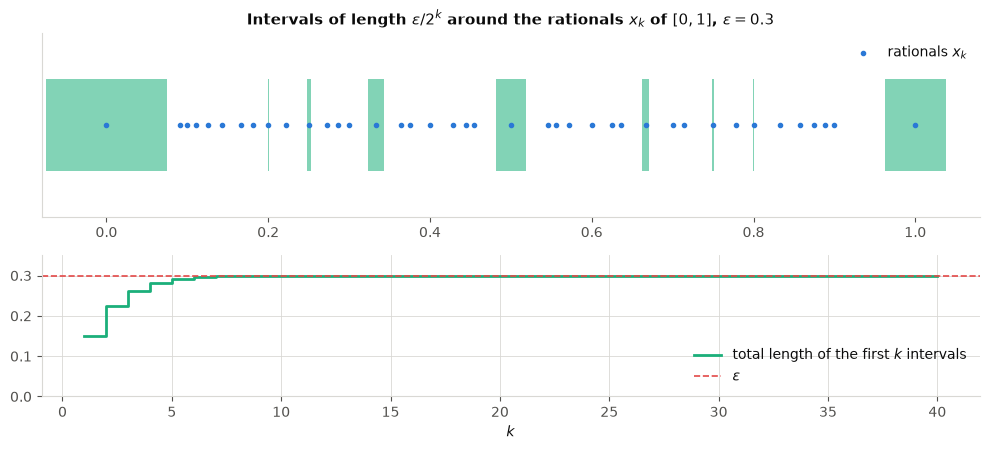

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})

from fractions import Fraction as Fr

rats = []
q = 1
while len(rats) < 40:
    for p in range(q + 1):
        r = Fr(p, q)
        if r not in rats:
            rats.append(r)
    q += 1
rats = rats[:40]
eps = 0.3

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 4.6), gridspec_kw={"height_ratios": [1.3, 1]})
for k, r in enumerate(rats, start=1):
    half = eps / 2 ** (k + 1)
    ax.add_patch(plt.Rectangle((float(r) - half, 0.25), 2 * half, 0.5, color=AQUA, alpha=0.55, lw=0))
ax.scatter([float(r) for r in rats], [0.5] * len(rats), s=9, color=BLUE, zorder=3, label="rationals $x_k$")
ax.set_xlim(-0.08, 1.08); ax.set_ylim(0, 1); ax.set_yticks([]); ax.grid(False)
ax.set_title(r"Intervals of length $\varepsilon/2^k$ around the rationals $x_k$ of $[0,1]$, $\varepsilon = 0.3$")
ax.legend(loc="upper right")
lengths = eps / 2.0 ** np.arange(1, 41)
ax2.step(np.arange(1, 41), np.cumsum(lengths), where="post", color=AQUA, lw=2, label="total length of the first $k$ intervals")
ax2.axhline(eps, color=RED, ls="--", lw=1.2, label=r"$\varepsilon$")
ax2.set_xlabel("$k$"); ax2.set_ylim(0, 0.35); ax2.legend(loc="lower right")
plt.tight_layout(); plt.show()


## 5\. The Outer Measure of a Box

We must check that outer measure gives a box its volume. This is not obvious: even for a rectangle, $m^*(R)$ is an infimum over all countable covers of $R$ by other rectangles, and it is not clear that it equals the area of $R$. The proof uses compactness, in the following form.

::: {#lem-finite-subcover}
## Finite Subcovers

Let $K \subseteq \mathbb{R}^n$ be closed and bounded. If $K \subseteq \bigcup_{\alpha} U_\alpha$ for a family of open sets $U_\alpha$, then finitely many of the $U_\alpha$ already cover $K$.
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-finite-subcover
Suppose not: no finite subfamily covers $K$. Enclose $K$ in a closed cube $Q_0$ and cut it into $2^n$ closed cubes of half the side. If each piece $K \cap Q$ were covered by finitely many $U_\alpha$, together they would cover $K$; so some piece $K \cap Q_1$ is not finitely covered. Repeating, we get closed cubes $Q_0 \supseteq Q_1 \supseteq Q_2 \supseteq \cdots$ with $\operatorname{diam} Q_m = 2^{-m} \operatorname{diam} Q_0 \to 0$ such that no $K \cap Q_m$ is finitely covered; in particular each $K \cap Q_m$ is non-empty.

Pick $x_m \in K \cap Q_m$. By the [Heine–Borel theorem](compactness.ipynb#the-heine-borel-theorem), $K$ is (sequentially) compact, so a subsequence of $(x_m)$ converges to some $p \in K$. For $j \ge m$ we have $x_j \in Q_m$, and $Q_m$ is closed, so $p \in Q_m$ for every $m$. Now $p$ lies in some $U_\alpha$, which is open, so it contains a ball $B_r(p)$. Choose $m$ with $\operatorname{diam} Q_m < r$; then $Q_m \subseteq B_r(p) \subseteq U_\alpha$, and the single set $U_\alpha$ covers $K \cap Q_m$, a contradiction. $\blacksquare$
:::

::: {#thm-outer-measure-of-box}
## Outer Measure of a Box

1. In $\mathbb{R}$: $m^*(I) = |I|$ for every bounded interval $I$.
2. In $\mathbb{R}^2$: $m^*(R) = |R|$ for every rectangle $R$.
3. In $\mathbb{R}^n$: $m^*(B) = |B|$ for every box $B$.
:::

We prove the case of $\mathbb{R}^2$. The case $n = 1$ is the same argument with intervals (or the special case of rectangles $I \times [0,1]$), and the proof in $\mathbb{R}^n$ is word for word the same with $n$-dimensional grids. (The one-dimensional case is often proved by induction on the number of intervals, an argument that does not extend easily to the plane.)

::: {.callout-tip collapse="true"}
## Proof of @thm-outer-measure-of-box
**Closed rectangles.** Let $R = [a, b] \times [c, d]$. We prove $m^*(R) \le |R|$ and $m^*(R) \ge |R|$.

*Step 1: $m^*(R) \le |R|$.* If $R$ were open it would cover itself. Since it is closed, enlarge its sides slightly: for every $\varepsilon > 0$ there is a single open rectangle containing $R$ with area at most $|R| + \varepsilon$. So the set of sums whose infimum is $m^*(R)$ contains numbers $\le |R| + \varepsilon$ for every $\varepsilon$, for instance numbers $\le |R| + \frac1n$ for all $n$. It may contain smaller numbers too, but its infimum cannot exceed $|R|$.

*Step 2: $m^*(R) \ge |R|$.* It suffices to show that **every** cover has total area at least $|R|$:
$$R \subseteq \bigcup_k R_k \implies \sum_k |R_k| \ge |R|,$$
because then the infimum of these sums is $\ge |R|$ as well. Geometrically this is clear: a room of $10\,\text{m}^2$ cannot be covered by rugs of total area less than $10\,\text{m}^2$. But the cover may be infinite, with rugs getting smaller and smaller, and we want a proof from the axioms rather than from geometric intuition.

Compactness helps. $R$ is closed and bounded and the $R_k$ are open, so by @lem-finite-subcover finitely many of them, say $R_1, \dots, R_N$, already cover $R$. Discarding the others only decreases the sum, so we may assume the cover is finite, $R_k = (a_k, b_k) \times (c_k, d_k)$ for $k = 1, \dots, N$.

With finitely many rectangles we can extend all their sides into lines and **grid** $R$. Let
$$a = x_0 < x_1 < \dots < x_r = b$$
be the points $a$, $b$ and those $a_k, b_k$ that lie in $[a, b]$, in increasing order; similarly $c = y_0 < y_1 < \dots < y_s = d$ from $c$, $d$ and the $c_k, d_k$ in $[c, d]$. The grid cells $Q_{ij} = [x_i, x_{i+1}] \times [y_j, y_{j+1}]$ cover $R$ and do not overlap except along edges. By an algebraic identity (no geometry needed),
$$|R| = (b - a)(d - c) = \Big(\sum_{i=0}^{r-1} (x_{i+1} - x_i)\Big)\Big(\sum_{j=0}^{s-1} (y_{j+1} - y_j)\Big) = \sum_{i,j} (x_{i+1} - x_i)(y_{j+1} - y_j) = \sum_{i,j} |Q_{ij}|. \tag{$*$}$$

*Each $R_k$ contributes the cells inside it.* The closure of $R_k$ meets $R$ in the rectangle $[\max(a, a_k), \min(b, b_k)] \times [\max(c, c_k), \min(d, d_k)]$ (if non-empty), whose sides are grid points. By the same identity its area is the sum of the areas of the cells it contains, so
$$\sum_{Q_{ij} \subseteq \overline{R_k}} |Q_{ij}| \le |R_k|.$$

*Every cell lies in some $\overline{R_k}$.* Let $p$ be the centre of $Q_{ij}$. Since $p \in R$, some $R_k$ contains $p$, so $a_k < p_x < b_k$. The number $a_k$ is either less than $a \le x_i$, or a grid point; since no grid point lies strictly between $x_i$ and $x_{i+1}$, and $a_k < p_x < x_{i+1}$, we get $a_k \le x_i$. In the same way $b_k \ge x_{i+1}$, $c_k \le y_j$ and $d_k \ge y_{j+1}$, so $Q_{ij} \subseteq \overline{R_k}$.

So each term of $(*)$ appears in at least one of the sums for $R_1, \dots, R_N$ (possibly in several: overlaps only help), and
$$|R| = \sum_{i,j} |Q_{ij}| \le \sum_{k=1}^N \sum_{Q_{ij} \subseteq \overline{R_k}} |Q_{ij}| \le \sum_{k=1}^N |R_k|.$$
Steps 1 and 2 give $m^*(R) = |R|$ for closed rectangles.

**Other rectangles.** If some sides of $R$ are missing, let $\varepsilon > 0$ and choose closed rectangles $S_1 \subseteq R \subseteq S_2$ with $|S_1| > |R| - \varepsilon$ (shrink the sides slightly) and $|S_2| < |R| + \varepsilon$ (enlarge them). By monotonicity and the closed case,
$$|R| - \varepsilon < |S_1| = m^*(S_1) \le m^*(R) \le m^*(S_2) = |S_2| < |R| + \varepsilon,$$
and letting $\varepsilon \to 0$ gives $m^*(R) = |R|$. $\blacksquare$
:::

::: {.callout-note}
## Intuition: Why the Grid Works
Overlapping rectangles are awkward to compare with $R$. Drawing every horizontal and vertical line that appears as a side turns the comparison into bookkeeping: $R$ is the union of the grid cells, every cell is claimed by at least one rectangle of the cover, and overlaps can only make the total larger. Geometric intuition guides the proof, but the proof itself uses only the definitions and compactness. The genuinely delicate point is the passage from an infinite cover to a finite one.
:::

So the edges of a rectangle do not affect its outer measure: they are sets of measure zero. The figure shows a finite cover of $R = [0,4] \times [0,3]$ by four open rectangles, the grid made from their sides, and the number of rectangles covering each cell; the code checks that every cell is covered and that the areas add up as in the proof.

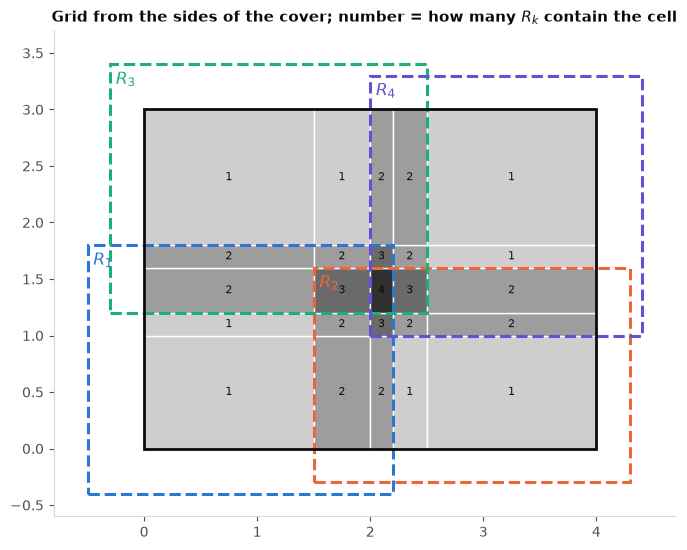

every cell lies in some closed R_k: True
|R| = 12.00 = sum of cells = 12.00 <= sum |R_k| = 22.94


In [2]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})

from matplotlib.patches import Rectangle

a, b, c, d = 0.0, 4.0, 0.0, 3.0
cover = [(-0.5, 2.2, -0.4, 1.8), (1.5, 4.3, -0.3, 1.6), (-0.3, 2.5, 1.2, 3.4), (2.0, 4.4, 1.0, 3.3)]
xs = sorted({a, b} | {t for (a1, b1, _, _) in cover for t in (a1, b1) if a <= t <= b})
ys = sorted({c, d} | {t for (_, _, c1, d1) in cover for t in (c1, d1) if c <= t <= d})

def contains_closure(rk, x0, x1, y0, y1):
    a1, b1, c1, d1 = rk
    return a1 <= x0 and x1 <= b1 and c1 <= y0 and y1 <= d1

fig, ax = plt.subplots(figsize=(8, 5.6))
cols = [BLUE, ORANGE, AQUA, VIOLET]
counts = []
for x0, x1 in zip(xs, xs[1:]):
    for y0, y1 in zip(ys, ys[1:]):
        n = sum(contains_closure(rk, x0, x1, y0, y1) for rk in cover)
        counts.append(n)
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor=plt.cm.Greys(0.12 + 0.18 * n), edgecolor="white", lw=1))
        ax.text((x0 + x1) / 2, (y0 + y1) / 2, str(n), ha="center", va="center", fontsize=8, color=INK)
for (a1, b1, c1, d1), col, k in zip(cover, cols, range(1, 5)):
    ax.add_patch(Rectangle((a1, c1), b1 - a1, d1 - c1, fill=False, edgecolor=col, lw=2.2, ls="--"))
    ax.text(a1 + 0.05, d1 - 0.18, f"$R_{k}$", color=col, fontsize=12)
ax.add_patch(Rectangle((a, c), b - a, d - c, fill=False, edgecolor=INK, lw=2))
ax.set_xlim(-0.8, 4.7); ax.set_ylim(-0.6, 3.7); ax.set_aspect("equal"); ax.grid(False)
ax.set_title("Grid from the sides of the cover; number = how many $R_k$ contain the cell")
plt.tight_layout(); plt.show()

cells_area = sum((x1 - x0) * (y1 - y0) for x0, x1 in zip(xs, xs[1:]) for y0, y1 in zip(ys, ys[1:]))
print("every cell lies in some closed R_k:", min(counts) >= 1)
print(f"|R| = {(b-a)*(d-c):.2f} = sum of cells = {cells_area:.2f} <= sum |R_k| = "
      f"{sum((b1-a1)*(d1-c1) for a1, b1, c1, d1 in cover):.2f}")


## 6\. Subadditivity

If $m^*$ were countably additive it would already be a measure on all subsets of $\mathbb{R}^n$, which is impossible. It is not even finitely additive: there are disjoint sets $A, B$ with $m^*(A \cup B) \ne m^*(A) + m^*(B)$. Such sets are pathological, so intertwined that although disjoint they share a lot of "boundary"; we do not construct them.

One inequality does hold always. Which one? Take $A = \mathbb{Q}$ and $B$ the irrationals in an interval: they are disjoint, but any cover of the rationals by intervals also catches irrationals, so covers of $A$ and of $B$ always overlap. The sum $m^*(A) + m^*(B)$ therefore counts too much, never too little. Precisely: a cover of $A$ together with a cover of $B$ is a cover of $A \cup B$, but $A \cup B$ may have cheaper covers that do not split into a cover of $A$ and a cover of $B$. So we expect $\le$.

::: {#lem-inf-epsilon}
## The Infimum Lemma

Let $S \subseteq \mathbb{R}$ and $a \in \mathbb{R}$. Then $\inf S \le a$ if and only if for every $\varepsilon > 0$ there is $s \in S$ with $s < a + \varepsilon$. (And $\inf S = a$ means, in addition, that every $s \in S$ satisfies $s \ge a$.)
:::

This is the [ε-characterization of the infimum](supremum-infimum.ipynb#the-infimum-greatest-lower-bound), a standard exercise.

::: {#thm-outer-measure-subadditive}
## Subadditivity

For all $A, B \subseteq \mathbb{R}^n$ (disjoint or not), $m^*(A \cup B) \le m^*(A) + m^*(B)$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-outer-measure-subadditive
If $m^*(A)$ or $m^*(B)$ is $\infty$ there is nothing to prove. Otherwise, by @lem-inf-epsilon we must show: for every $\varepsilon > 0$ there is a cover of $A \cup B$ by open boxes with total volume less than $m^*(A) + m^*(B) + \varepsilon$. Choose a cover of $A$ with total volume less than $m^*(A) + \frac\varepsilon2$ and a cover of $B$ with total volume less than $m^*(B) + \frac\varepsilon2$. Together they cover $A \cup B$, with total volume less than $m^*(A) + m^*(B) + \varepsilon$ (possibly they overlap, which only makes $m^*(A \cup B)$ smaller than this). $\blacksquare$
:::

A function with this property is called **subadditive**. By induction it gives **finite subadditivity**: $m^*\big(\bigcup_{i=1}^n E_i\big) \le \sum_{i=1}^n m^*(E_i)$, since $m^*\big(\bigcup_{i=1}^{n-1} E_i \cup E_n\big) \le m^*\big(\bigcup_{i=1}^{n-1} E_i\big) + m^*(E_n)$. (Some books call this property subadditivity.)

For countably many sets, letting $n \to \infty$ in the finite version does not work: the right-hand side converges to $\sum_i m^*(E_i)$, but nothing is known about the left-hand side, because no continuity property of $m^*$ has been proved. The covering argument must be redone.

::: {#thm-countable-subadditivity}
## Countable Subadditivity

For all $E_1, E_2, \dots \subseteq \mathbb{R}^n$,
$$m^*\Big(\bigcup_{i=1}^\infty E_i\Big) \le \sum_{i=1}^\infty m^*(E_i).$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-countable-subadditivity
If some $m^*(E_i) = \infty$ the claim is trivial, so assume all are finite. By @lem-inf-epsilon we need, for every $\varepsilon > 0$, a cover of $\bigcup_i E_i$ with total volume at most $\sum_i m^*(E_i) + \varepsilon$. Giving every $E_i$ a cover that wastes $\frac\varepsilon2$ would waste $\infty$ in total; the extra amounts must be controlled by a convergent series. So choose, for each $i$, a cover of $E_i$ by open boxes $R_{i,1}, R_{i,2}, \dots$ with
$$\sum_{k} |R_{i,k}| < m^*(E_i) + \frac{\varepsilon}{2^i}.$$
The doubly indexed family $\{R_{i,k}\}_{i,k}$ is countable (a countable union of countable families) and covers $\bigcup_i E_i$. Its total volume, a sum of non-negative terms that can be added in any order, is
$$\sum_i \sum_k |R_{i,k}| \le \sum_i \Big(m^*(E_i) + \frac{\varepsilon}{2^i}\Big) = \sum_i m^*(E_i) + \varepsilon. \qquad \blacksquare$$
:::

::: {.callout-note}
## Outer Measures in General
Monotonicity, $m^*(\emptyset) = 0$ and countable subadditivity are all we will use about $m^*$ from now on. One can forget $\mathbb{R}^n$ altogether: a function $\mu^* : 2^X \to [0, \infty]$ on any set $X$ with these three properties is called an **outer measure**, and the construction of the next notes turns any outer measure into a measure.
:::

## 7\. Translation Invariance

::: {#prp-outer-measure-translation}
## Translation Invariance

For $E \subseteq \mathbb{R}^n$ and $y \in \mathbb{R}^n$, $m^*(E + y) = m^*(E)$, where $E + y = \{x + y : x \in E\}$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-outer-measure-translation
The boxes $R_k$ cover $E$ if and only if the translated boxes $R_k + y$ cover $E + y$, and translation does not change the volume of a box: $|R_k + y| = |R_k|$. So both infima are taken over the same set of numbers. $\blacksquare$
:::